# Expedition33 SAS

## Setup

In [4]:
import ast
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
import mercury as mr

DATA_DIR = Path('Data') if Path('Data/people_data.csv').exists() else Path('.') #To check if the Data is in the Data path first, for branch

df_people = pd.read_csv(DATA_DIR / '../Data/people_data.csv')
df_logs = pd.read_csv(DATA_DIR / '../Data/security_logs.csv')
df_location = pd.read_csv(DATA_DIR / '../Data/location_data.csv')

print(f"People Shape: {df_people.shape} \nLogs Shape: {df_logs.shape} \nLocation Shape: {df_location.shape}")
df_people.head()
#df_logs.head()
#df_location.head()

People Shape: (163, 9) 
Logs Shape: (662, 4) 
Location Shape: (14, 4)


,Student ID,Name,Age,Sex,Year of Study,Subject,Height,Hair colour,Societies
0,2611516B,Carolyn Bond,25,Female,3,English Literature,169,#23d620,"['Soup Society', 'Sexpression', 'Dr Who Society']"
1,2645195D,Jordan Dickinson,21,Male,3,Computing Science,164,#cbe253,"['Italian Society', 'Bad Movie Society', 'Clas..."
2,2527287T,Danny Thomas,23,Male,4,Philosophy,168,#6ae8ce,"['Back to Yoga Society', 'Big Band Society']"
3,2878087C,Danielle Cox,24,Female,1,Physics,171,#aefcc1,"['Skate Society', 'Philosophy Society', 'Juggl..."
4,2595487S,Martin Smith,27,Male,4,English Literature,162,#d14336,"['Accapella Society', 'Dr Who Society']"


In [5]:

SURFACE, INK, INK_2, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#8a8984', '#e8e7e3'
QUIET = '#c9c8c3'                      
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6', '#008300', '#e34948']
CRITICAL = '#d03b3b'                   
BLUES = LinearSegmentedColormap.from_list(
    'blues', ['#f4f8fd', '#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'])

plt.rcParams.update({
    'font.family': ['Inter', 'DejaVu Sans'], 'font.size': 11,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'figure.titlesize': 17, 'figure.titleweight': 'semibold',
    'axes.titlesize': 13, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'xtick.major.size': 0, 'ytick.major.size': 0,
    'text.color': INK, 'legend.frameon': False,
})

def headline(fig, title, subtitle=None):
    """Big title that states the finding, with a smaller line explaining how to read the chart."""
    h = fig.get_figheight()
    fig.suptitle(title, x=0.012, y=1 - 0.18 / h, ha='left', va='top')
    if subtitle:
        fig.text(0.012, 1 - 0.55 / h, subtitle, ha='left', va='top', color=INK_2, fontsize=11)
    fig.subplots_adjust(top=1 - (1.05 if subtitle else 0.75) / h)

def label_outward(ax, centre, direction, dist, title, detail):
    """Two-line label placed outside a shape, on the side facing away from the middle of the chart."""
    d = np.asarray(direction, float); d = d / (np.linalg.norm(d) or 1)
    x, y = np.asarray(centre) + d * dist
    ha = 'left' if d[0] > 0.6 else 'right' if d[0] < -0.6 else 'center'
    
    up = 6 if d[1] >= -0.35 else -6
    ty, dy = (up + 8, up - 8) if d[1] >= -0.35 else (up - 4, up - 20)
    if d[1] > 0.35: ty, dy = 22, 6
    ax.annotate(title, (x, y), xytext=(0, ty), textcoords='offset points', ha=ha, va='center',
                fontsize=12.5, weight='semibold', path_effects=HALO, zorder=10)
    ax.annotate(detail, (x, y), xytext=(0, dy), textcoords='offset points', ha=ha, va='center',
                fontsize=10.5, color=INK_2, path_effects=HALO, zorder=10)

HALO = [pe.withStroke(linewidth=3, foreground=SURFACE)]   

In [6]:

SOCIETY_WEIGHT = 1.0      # weight added per shared society
MIN_OVERLAP_MIN = 15      # ignore co-locations shorter than this (minutes)
MINUTES_PER_UNIT = 60     # 60 overlapping minutes add 1.0 to an edge's weight
MIN_COMMUNITY_SIZE = 5    # communities smaller than this are left out of the summaries
SEED = 42                 # makes Louvain and the layouts reproducible

## Step 1 · Load and clean the data
The raw files have a few small errors that would otherwise break the joins between them:

- **Societies** are saved as text, in two different formats, sometimes blank, and occasionally with a society listed twice.
- **Student IDs** in the logs don't always match the student list: one has a lower-case letter, one a wrong digit. We repair them by matching on the student's name.
- **One building name is misspelt** in the logs (`Queen Maragret Building`).
- **Times** are `HHMM-HHMM` text, and some visits run past midnight.

In [7]:
df_people = pd.read_csv(DATA_DIR / 'people_data.csv')
df_logs = pd.read_csv(DATA_DIR / 'security_logs.csv')
df_location = pd.read_csv(DATA_DIR / 'location_data.csv')

def parse_societies(value):
    if pd.isna(value) or str(value).strip().upper() in ('', 'N/A', 'NAN'):
        return []
    return sorted(set(ast.literal_eval(value)))# handles [...] and {...}, drops duplicates

df_people['Societies raw'] = df_people['Societies']# kept for the consistency checks
df_people['Societies'] = df_people['Societies'].apply(parse_societies)
df_people['Student ID'] = df_people['Student ID'].str.strip().str.upper()


valid_ids = set(df_people['Student ID'])
name_to_id = dict(zip(df_people['Name'], df_people['Student ID']))
df_logs['Raw ID'] = df_logs['Student ID']
df_logs['Student ID'] = df_logs['Student ID'].str.strip().str.upper()
unknown = ~df_logs['Student ID'].isin(valid_ids)
df_logs.loc[unknown, 'Student ID'] = df_logs.loc[unknown, 'Name'].map(name_to_id)


LOCATION_FIXES = {'Queen Maragret Building': 'Queen Margaret Union'}
df_logs['Raw Location'] = df_logs['Location']
df_logs['Location'] = df_logs['Location'].replace(LOCATION_FIXES)


def hhmm_to_min(s):
    s = str(s).zfill(4)
    return int(s[:2]) * 60 + int(s[2:])

t = df_logs['Time'].str.split('-', expand=True)
df_logs['Start'], df_logs['End'] = t[0].apply(hhmm_to_min), t[1].apply(hhmm_to_min)
df_logs.loc[df_logs['End'] <= df_logs['Start'], 'End'] += 24 * 60
df_logs['Duration'] = df_logs['End'] - df_logs['Start']


hours = df_location.set_index('Building Name')['Opening Times'].str.split('-', expand=True)
hours.columns = ['Open', 'Close']
hours = hours.apply(lambda c: c.map(hhmm_to_min))
hours.loc[hours['Close'] <= hours['Open'], 'Close'] += 24 * 60
hours.loc[(hours['Open'] == 0) & (hours['Close'] == 24 * 60), :] = [0, 48 * 60]  # the park never closes

def outside_hours(row):
    o, c = hours.loc[row['Location'], ['Open', 'Close']]
    start, end = row['Start'], row['End']
    if start < o: # early hours belong to the previous night
        start, end = start + 24 * 60, end + 24 * 60
    return not (o <= start and end <= c)

df_logs['Outside hours'] = df_logs.apply(outside_hours, axis=1)

fixed_ids = df_logs.loc[df_logs['Raw ID'] != df_logs['Student ID'], ['Raw ID', 'Student ID', 'Name']].drop_duplicates()
print(f'{len(df_people)} students · {len(df_logs)} log entries · {len(df_location)} buildings')
print(f'Repaired {len(fixed_ids)} student IDs and {(df_logs["Raw Location"] != df_logs["Location"]).sum()} building name')
fixed_ids

163 students · 662 log entries · 14 buildings
Repaired 2 student IDs and 1 building name


,Raw ID,Student ID,Name
5,2912324G,2712324G,Jonny Craig
85,2813225b,2813225B,Stuart Wands


## Step 2 · Build the network
Each **student is a dot**. Two students are joined by a line if:

- they **belong to the same society**: each shared society adds 1 to the strength of the link; or
- they were **in the same building at the same time** for at least 15 minutes: each hour together adds 1.

Sitting in the same lecture counts as being together, so students of the same subject end up strongly linked. That is real contact, and it is why the communities in Step 3 line up with subjects.

In [8]:
# Society ties
society_pairs = {}
for society, members in (df_people.explode('Societies').dropna(subset=['Societies'])
                         .groupby('Societies')['Name']):
    for u, v in itertools.combinations(sorted(members), 2):
        society_pairs.setdefault((u, v), []).append(society)

# Co-location ties: overlapping visits to the same building
logs = df_logs.merge(df_people[['Student ID']], on='Student ID')
id_to_name = dict(zip(df_people['Student ID'], df_people['Name']))
colocation = {}
for place, visits in logs.groupby('Location'):
    visits = visits.sort_values('Start').to_dict('records')
    for i, a in enumerate(visits):
        for b in visits[i + 1:]:
            if b['Start'] >= a['End']:
                break
            if a['Student ID'] == b['Student ID']:
                continue
            overlap = min(a['End'], b['End']) - b['Start']
            if overlap < MIN_OVERLAP_MIN:
                continue
            u, v = sorted([id_to_name[a['Student ID']], id_to_name[b['Student ID']]])
            e = colocation.setdefault((u, v), {'minutes': 0, 'places': set()})
            e['minutes'] += overlap
            e['places'].add(place)

# One weighted graph
G = nx.Graph()
for _, r in df_people.iterrows():
    G.add_node(r['Name'], subject=r['Subject'], year=r['Year of Study'], age=r['Age'])
for (u, v), socs in society_pairs.items():
    G.add_edge(u, v, weight=SOCIETY_WEIGHT * len(socs), societies=socs, minutes=0, places=[])
for (u, v), info in colocation.items():
    if not G.has_edge(u, v):
        G.add_edge(u, v, weight=0.0, societies=[], minutes=0, places=[])
    G[u][v]['minutes'] = info['minutes']
    G[u][v]['places'] = sorted(info['places'])
    G[u][v]['weight'] += info['minutes'] / MINUTES_PER_UNIT

print(f'{G.number_of_nodes()} students · {G.size()} links '
      f'({len(society_pairs)} from societies, {len(colocation)} from being in the same place)')

163 students · 6048 links (1432 from societies, 5191 from being in the same place)


## Step 3 · Find the communities
The Louvain method splits the network into groups where students are more strongly linked to each other than to everyone else. Each community gets a name from its two most common subjects, and keeps the same colour in every chart below.

In [9]:
communities_list = sorted(nx.community.louvain_communities(G, weight='weight', seed=SEED),
                          key=len, reverse=True)
partition = {n: cid for cid, members in enumerate(communities_list) for n in members}
df_people['Community'] = df_people['Name'].map(partition)

SHORT = {'Computing Science': 'Computing', 'Veterinary Medicine': 'Vet Med',
         'English Literature': 'English Lit', 'Mathematics': 'Maths'}
def community_name(cid):
    top = df_people.loc[df_people['Community'] == cid, 'Subject'].value_counts()
    names = [SHORT.get(s, s) for s in top.index[:2]]
    return names[0] if len(top) == 1 or top.iloc[1] < 3 else f'{names[0]} & {names[1]}'

COM_NAME = {c: community_name(c) for c in range(len(communities_list))}
COM_COLOR = {c: SERIES[c % len(SERIES)] for c in range(len(communities_list))}
main_coms = [c for c, m in enumerate(communities_list) if len(m) >= MIN_COMMUNITY_SIZE]

modularity = nx.community.modularity(G, communities_list, weight='weight')
print(f'{len(communities_list)} communities · modularity {modularity:.2f}')
pd.DataFrame({'Community': [COM_NAME[c] for c in main_coms],
              'Students': [len(communities_list[c]) for c in main_coms]})

6 communities · modularity 0.23


,Community,Students
0,Maths & Vet Med,39
1,Physics & Chemistry,30
2,Medicine & English Lit,30
3,Computing & Business,27
4,Philosophy,22
5,Engineering & Business,15


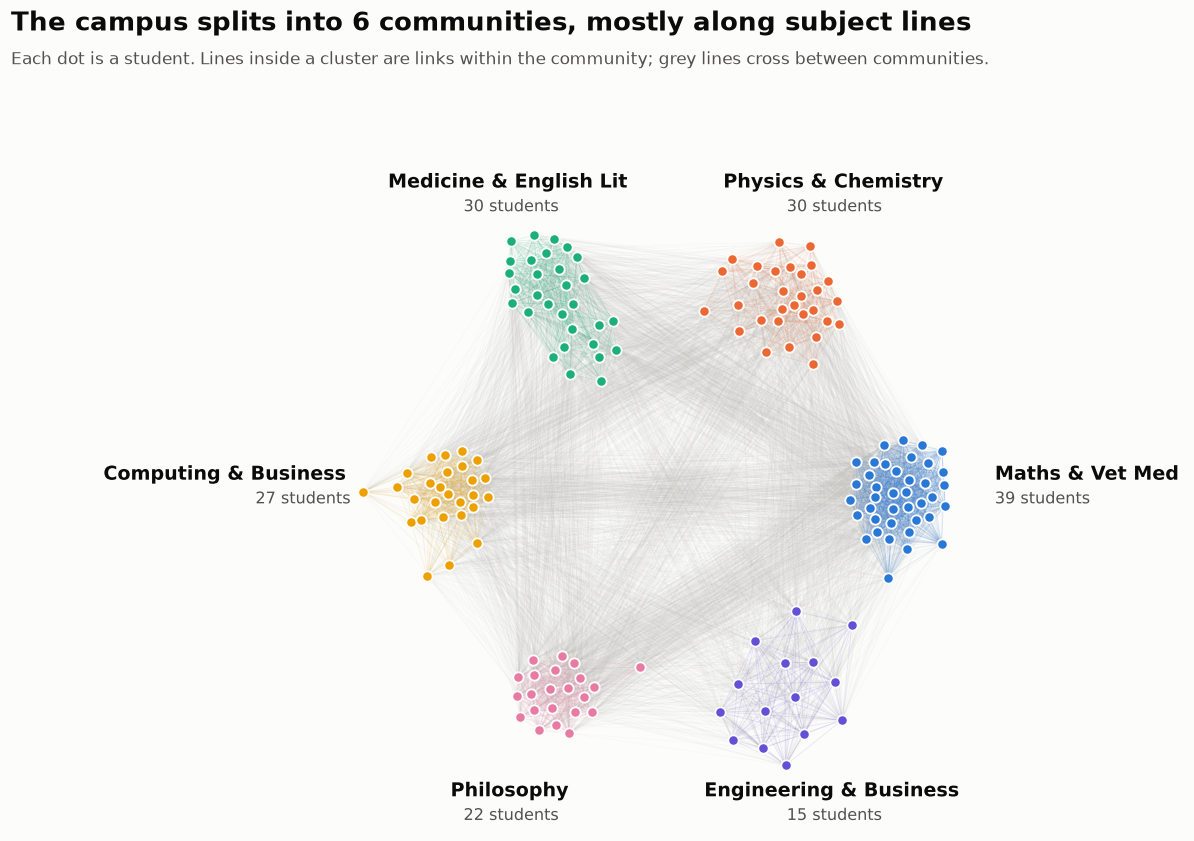

In [10]:
#Community map
ring = nx.circular_layout(main_coms, scale=3.2)
pos = {}
for c in main_coms:
    sub = G.subgraph(communities_list[c])
    local = nx.spring_layout(sub, weight='weight', seed=SEED, k=0.9)
    pts = np.array(list(local.values()))
    pts = (pts - pts.mean(0)) / (np.abs(pts).max() or 1) * 1.15
    pos.update({n: ring[c] + p for n, p in zip(local, pts)})

fig, ax = plt.subplots(figsize=(12, 9))
headline(fig, f'The campus splits into {len(main_coms)} communities, mostly along subject lines',
         'Each dot is a student. Lines inside a cluster are links within the community; grey lines cross between communities.')
inter = [(u, v) for u, v in G.edges() if u in pos and v in pos and partition[u] != partition[v]]
nx.draw_networkx_edges(G, pos, edgelist=inter, edge_color=QUIET, alpha=0.08, width=0.5, ax=ax)
for c in main_coms:
    intra = [(u, v) for u, v in G.subgraph(communities_list[c]).edges()]
    nx.draw_networkx_edges(G, pos, edgelist=intra, edge_color=COM_COLOR[c], alpha=0.12, width=0.6, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=list(communities_list[c]), node_size=46,
                           node_color=COM_COLOR[c], edgecolors=SURFACE, linewidths=1.2, ax=ax)
    label_outward(ax, ring[c], ring[c], 1.35, COM_NAME[c], f'{len(communities_list[c])} students')
ax.set_xlim(-7.2, 7.2); ax.set_ylim(-4.7, 4.9); ax.set_aspect('equal'); ax.axis('off')
plt.show()

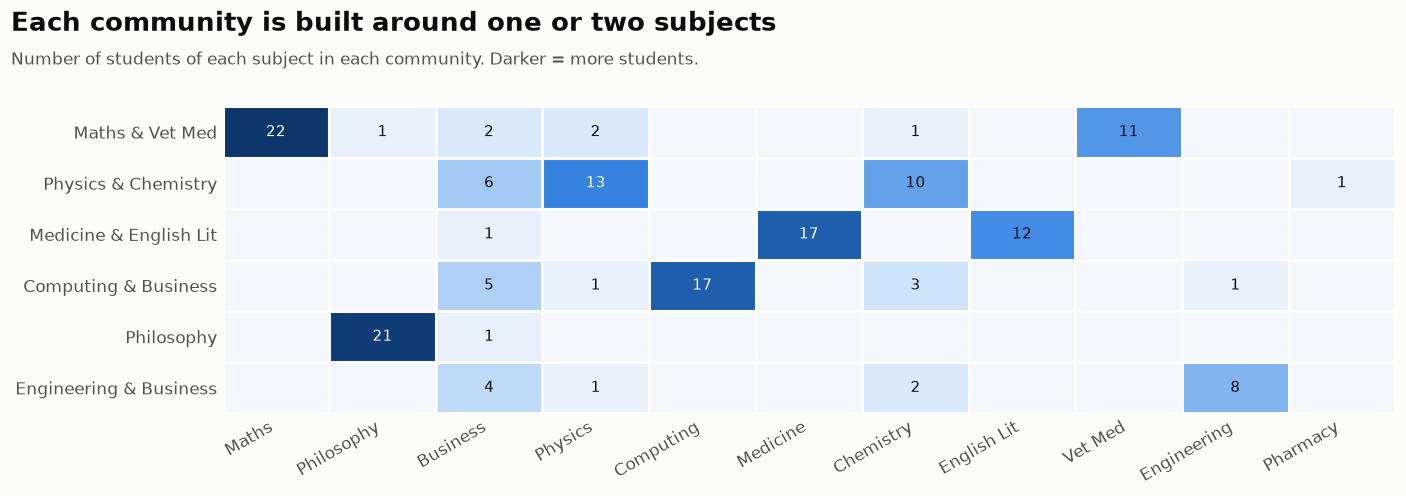

In [11]:
#About Community Composition
order = [COM_NAME[c] for c in main_coms]
comp = (df_people[df_people['Community'].isin(main_coms)]
        .assign(Community=lambda d: d['Community'].map(COM_NAME))
        .pivot_table(index='Community', columns='Subject', values='Name', aggfunc='count', fill_value=0)
        .reindex(order))
comp = comp[comp.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(13, 4.8))
headline(fig, 'Each community is built around one or two subjects',
         'Number of students of each subject in each community. Darker = more students.')
im = ax.imshow(comp.values, cmap=BLUES, aspect='auto', vmin=0)
for i in range(comp.shape[0]):
    for j in range(comp.shape[1]):
        v = comp.values[i, j]
        if v:
            ax.text(j, i, v, ha='center', va='center', fontsize=10,
                    color='white' if v > comp.values.max() * 0.55 else INK)
ax.set_xticks(range(comp.shape[1]), [SHORT.get(s, s) for s in comp.columns], rotation=30, ha='right')
ax.set_yticks(range(comp.shape[0]), comp.index)
for side in ax.spines.values(): side.set_visible(False)
ax.set_xticks(np.arange(-.5, comp.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, comp.shape[0]), minor=True)
ax.grid(which='minor', color=SURFACE, linewidth=2); ax.tick_params(which='minor', length=0)
plt.subplots_adjust(bottom=0.2, left=0.16, right=0.98)
plt.show()

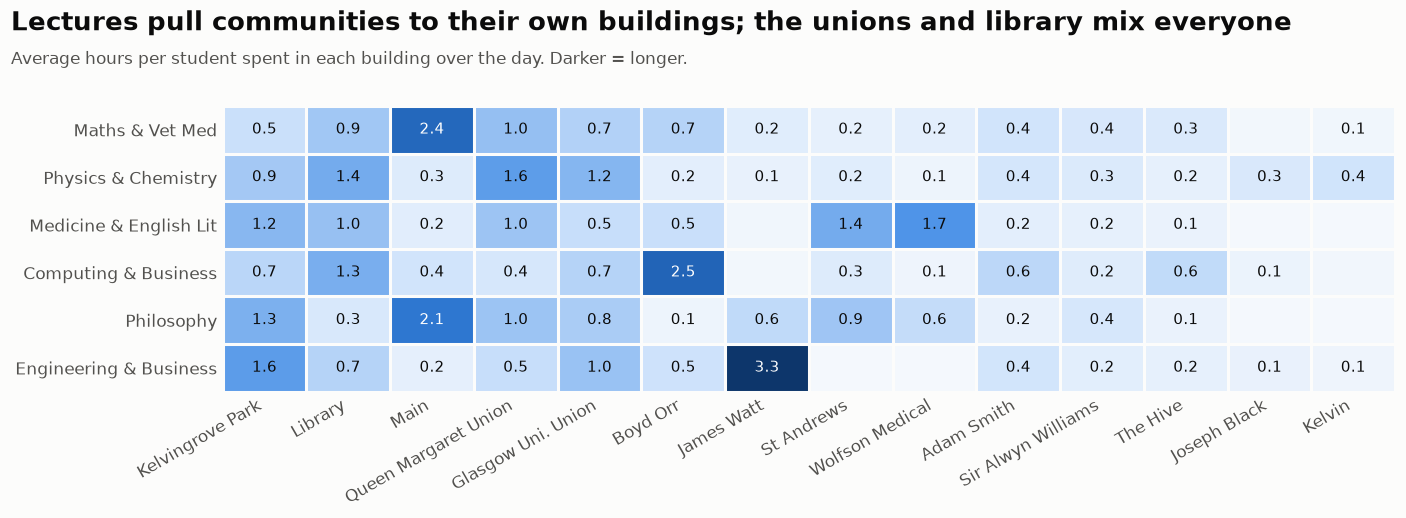

In [12]:
# ---- Where each community spends its time ----
logs_c = logs.assign(Community=logs['Student ID'].map(df_people.set_index('Student ID')['Community']))
logs_c = logs_c[logs_c['Community'].isin(main_coms)]
per_student = (logs_c.pivot_table(index='Community', columns='Location', values='Duration',
                                  aggfunc='sum', fill_value=0) / 60)
per_student = per_student.div([len(communities_list[c]) for c in per_student.index], axis=0)
per_student.index = per_student.index.map(COM_NAME)
per_student = per_student.reindex(order)
per_student = per_student[per_student.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(13, 4.8))
headline(fig, 'Lectures pull communities to their own buildings; the unions and library mix everyone',
         'Average hours per student spent in each building over the day. Darker = longer.')
ax.imshow(per_student.values, cmap=BLUES, aspect='auto', vmin=0)
for i in range(per_student.shape[0]):
    for j in range(per_student.shape[1]):
        v = per_student.values[i, j]
        if v >= 0.05:
            ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=9.5,
                    color='white' if v > per_student.values.max() * 0.55 else INK)
ax.set_xticks(range(per_student.shape[1]),
              [c.replace(' Building', '').replace('Glasgow University', 'Glasgow Uni.') for c in per_student.columns],
              rotation=30, ha='right')
ax.set_yticks(range(per_student.shape[0]), per_student.index)
for side in ax.spines.values(): side.set_visible(False)
ax.set_xticks(np.arange(-.5, per_student.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, per_student.shape[0]), minor=True)
ax.grid(which='minor', color=SURFACE, linewidth=2); ax.tick_params(which='minor', length=0)
plt.subplots_adjust(bottom=0.24, left=0.16, right=0.98)
plt.show()

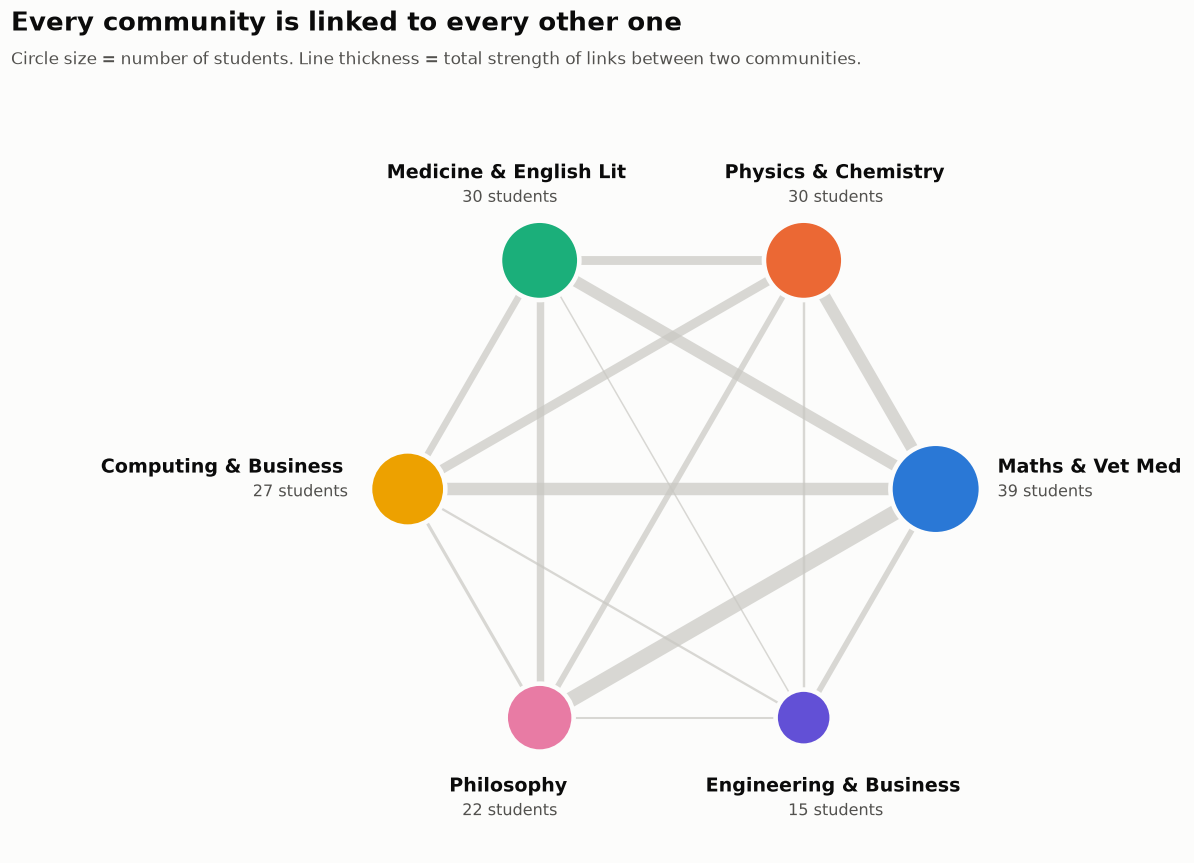

In [ ]:
# Community strength
blocks = [set(communities_list[c]) for c in main_coms]
ind = nx.quotient_graph(G.subgraph(set().union(*blocks)), blocks, relabel=False,
                        edge_data=lambda b, c: {'weight': sum(G[u][v]['weight'] for u in b for v in c if G.has_edge(u, v))})
ind = nx.relabel_nodes(ind, {b: partition[next(iter(b))] for b in ind.nodes()})

fig, ax = plt.subplots(figsize=(12, 9))
headline(fig, 'Every community is linked to every other one',
         'Circle size = number of students. Line thickness = total strength of links between two communities.')
w = np.array([ind[u][v]['weight'] for u, v in ind.edges()])
nx.draw_networkx_edges(ind, ring, width=1 + 9 * (w - w.min()) / (np.ptp(w) or 1), edge_color=QUIET, alpha=0.7, ax=ax)
nx.draw_networkx_nodes(ind, ring, nodelist=main_coms, node_color=[COM_COLOR[c] for c in main_coms],
                       node_size=[90 * len(communities_list[c]) for c in main_coms],
                       edgecolors=SURFACE, linewidths=3, ax=ax)
for c in main_coms:
    label_outward(ax, ring[c], ring[c], 0.75, COM_NAME[c], f'{len(communities_list[c])} students')
ax.set_xlim(-6.2, 6.2); ax.set_ylim(-4.4, 4.4); ax.set_aspect('equal'); ax.axis('off')
plt.show()

## Step 4 · Find the consistent connector
We want one student who:

1. **gives consistent data**: their profile and logs agree with each other and with the campus rules;
2. **keeps regular hours**: every visit is inside opening times, and they attend their own lecture in full;
3. **connects people across groups and buildings**.


First we check every student for inconsistencies. Anyone with even one is ruled out.

In [ ]:
#Lecture timetable, from the building descriptions in location_data.csv
LECTURES = {
    'Computing Science':   ('Boyd Orr Building',        '1000', '1200'),
    'Engineering':         ('James Watt Building',      '1000', '1300'),
    'Business':            ('Adam Smith Building',      '1000', '1100'),
    'Philosophy':          ('Main Building',            '0900', '1100'),
    'Veterinary Medicine': ('Main Building',            '1000', '1200'),
    'Mathematics':         ('Main Building',            '1100', '1300'),
    'Medicine':            ('Wolfson Medical Building', '1300', '1500'),
    'English Literature':  ('St Andrews Building',      '0900', '1200'),
    'Chemistry':           ('Joseph Black Building',    '1000', '1100'),
    'Physics':             ('Kelvin Building',          '0900', '1100'),
}
LECTURES = {k: (b, hhmm_to_min(s), hhmm_to_min(e)) for k, (b, s, e) in LECTURES.items()}


ID_YEAR = {'4': 5, '5': 4, '6': 3, '7': 2, '8': 1}

def check_student(row):
    sid, name, issues = row['Student ID'], row['Name'], []
    if sid[-1] != name.split()[-1][0].upper():
        issues.append('ID letter does not match surname')
    if ID_YEAR.get(sid[1]) != row['Year of Study']:
        issues.append('ID year does not match year of study')
    raw = str(row['Societies raw'])
    if raw.startswith('{'):
        issues.append('societies saved in a different format')
    if raw.startswith(('[', '{')) and len(ast.literal_eval(raw)) != len(set(ast.literal_eval(raw))):
        issues.append('society listed twice')

    g = df_logs[df_logs['Student ID'] == sid].sort_values('Start')
    if g.empty:
        return issues + ['no log entries']
    if (g['Raw ID'] != sid).any():
        issues.append('logged under a different ID')
    if (g['Raw Location'] != g['Location']).any():
        issues.append('misspelt building in log')
    if g['Outside hours'].any():
        issues.append('visit outside opening hours')
    if (g['Start'].values[1:] < g['End'].values[:-1]).any():
        issues.append('in two places at once')
    if row['Age'] < 18 and (g['Location'] == 'The Hive').any():
        issues.append('under 18 at The Hive')
    if row['Subject'] in LECTURES:
        b, s, e = LECTURES[row['Subject']]
        att = g[(g['Location'] == b) & (g['Start'] < e) & (g['End'] > s)]
        if att.empty:
            issues.append('missed own lecture')
        elif not ((att['Start'] == s) & (att['End'] == e)).any():
            issues.append('only part of own lecture')
    return issues

df_people['Issues'] = df_people.apply(check_student, axis=1)
df_people['Consistent'] = df_people['Issues'].str.len() == 0
CONSISTENT = dict(zip(df_people['Name'], df_people['Consistent']))

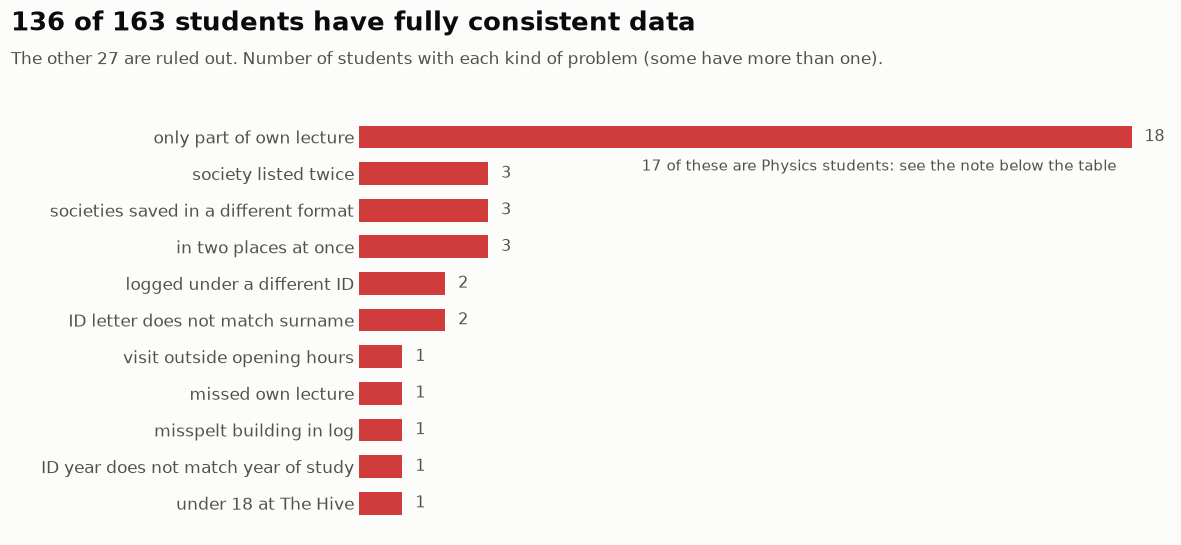

,Name,Subject,Year of Study,Issues
0,Abdul Murphy,English Literature,2,misspelt building in log; visit outside openin...
1,Alan Allen,Physics,3,only part of own lecture
2,Alice Patterson,Engineering,2,societies saved in a different format; in two ...
3,Amy Powell,Physics,2,only part of own lecture
4,Anne Hussain,Physics,4,only part of own lecture
5,Annette James,Physics,2,only part of own lecture
6,Anthony Hughes,Physics,2,only part of own lecture
7,Danielle Cox,Physics,1,only part of own lecture
8,Deborah Carter,Physics,5,only part of own lecture
9,Fiona Miah,Physics,4,only part of own lecture


In [ ]:
#Ruling out students:
counts = df_people['Issues'].explode().dropna().value_counts().sort_values()
n_out, n_in = (~df_people['Consistent']).sum(), df_people['Consistent'].sum()

fig, ax = plt.subplots(figsize=(11, 5.2))
headline(fig, f'{n_in} of {len(df_people)} students have fully consistent data',
         f'The other {n_out} are ruled out. Number of students with each kind of problem (some have more than one).')
bars = ax.barh(counts.index, counts.values, color=CRITICAL, height=0.62)
for b, v in zip(bars, counts.values):
    ax.text(v + 0.3, b.get_y() + b.get_height() / 2, str(v), va='center', fontsize=10.5, color=INK_2)
n_phys = df_people[df_people['Issues'].apply(lambda i: 'only part of own lecture' in i)
                   & (df_people['Subject'] == 'Physics')].shape[0]
if n_phys:
    ax.annotate(f'{n_phys} of these are Physics students: see the note below the table',
                (counts['only part of own lecture'], list(counts.index).index('only part of own lecture')),
                xytext=(-10, -22), textcoords='offset points', ha='right', fontsize=10, color=INK_2)
ax.spines['left'].set_visible(False); ax.spines['bottom'].set_visible(False)
ax.set_xticks([])
plt.subplots_adjust(left=0.3, right=0.97, bottom=0.05)
plt.show()

df_people.loc[~df_people['Consistent'], ['Name', 'Subject', 'Year of Study', 'Issues']] \
    .assign(Issues=lambda d: d['Issues'].str.join('; ')).sort_values('Name').reset_index(drop=True)

### Ranking the consistent students as connectors
Each consistent student gets a **bridge score** from three measures, given equal weight:

 **Spread**: how evenly their links are spread across communities rather than concentrated in their own.
 **Buildings**: how many different buildings they visited.
 **Go-between**: how often they sit on the shortest path between two other students.

In [16]:
def spread(n):
    by_com = {}
    for v, d in G[n].items():
        by_com[partition[v]] = by_com.get(partition[v], 0) + d['weight']
    total = sum(by_com.values())
    return 1 - sum((w / total) ** 2 for w in by_com.values()) if total else 0

betweenness = nx.betweenness_centrality(G)
buildings = logs.groupby('Student ID')['Location'].nunique()

scores = df_people[['Student ID', 'Name', 'Subject', 'Year of Study', 'Community', 'Consistent']].copy()
scores['Spread'] = scores['Name'].map(spread)
scores['Buildings'] = scores['Student ID'].map(buildings).fillna(0).astype(int)
scores['Go-between'] = scores['Name'].map(betweenness)
scores['Ties outside own community'] = scores['Name'].map(lambda n: sum(partition[v] != partition[n] for v in G[n]))
scores['Communities reached'] = scores['Name'].map(lambda n: len({partition[v] for v in G[n]}))

candidates = scores[scores['Consistent']].copy()
candidates['Bridge score'] = candidates[['Spread', 'Buildings', 'Go-between']].rank(pct=True).mean(axis=1)
candidates = candidates.sort_values('Bridge score', ascending=False).reset_index(drop=True)
target = candidates.loc[0, 'Name']
TARGET_ID = candidates.loc[0, 'Student ID']
print('Most consistent connector:', target)

Most consistent connector: Eleanor Marsh


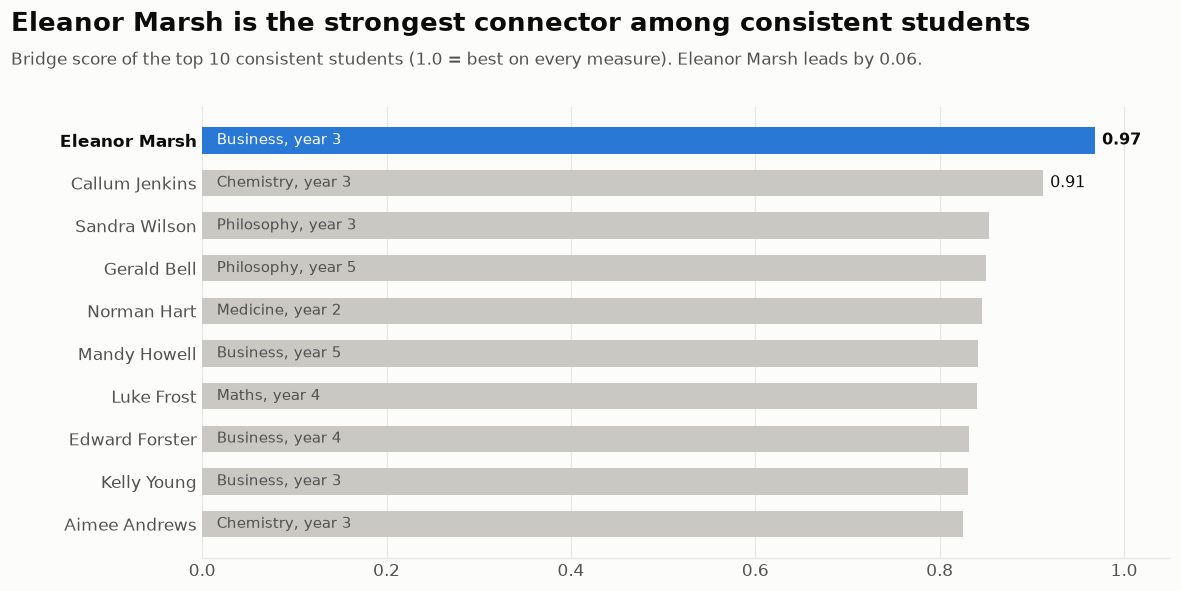

,Name,Subject,Year of Study,Communities reached,Ties outside own community,Buildings,Spread,Go-between,Bridge score,Community
0,Eleanor Marsh,Business,3,6,79,5,0.827,0.007,0.968,Physics & Chemistry
1,Callum Jenkins,Chemistry,3,6,76,5,0.804,0.006,0.912,Physics & Chemistry
2,Sandra Wilson,Philosophy,3,6,78,5,0.766,0.006,0.853,Philosophy
3,Gerald Bell,Philosophy,5,6,66,5,0.797,0.005,0.850,Philosophy
4,Norman Hart,Medicine,2,6,62,5,0.786,0.005,0.846,Medicine & English Lit
5,Mandy Howell,Business,5,6,76,4,0.830,0.005,0.842,Engineering & Business
6,Luke Frost,Mathematics,4,6,75,6,0.744,0.007,0.841,Maths & Vet Med
7,Edward Forster,Business,4,6,69,4,0.827,0.005,0.832,Computing & Business
8,Kelly Young,Business,3,6,62,5,0.782,0.005,0.831,Physics & Chemistry
9,Aimee Andrews,Chemistry,3,6,67,4,0.821,0.005,0.825,Engineering & Business


In [17]:
# ---- Leaderboard ----
top = candidates.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5.6))
lead = candidates.loc[0, 'Bridge score'] - candidates.loc[1, 'Bridge score']
headline(fig, f'{target} is the strongest connector among consistent students',
         f'Bridge score of the top 10 consistent students (1.0 = best on every measure). '
         f'{target} leads by {lead:.2f}.')
colors = [SERIES[0] if n == target else QUIET for n in top['Name']]
bars = ax.barh(top['Name'], top['Bridge score'], color=colors, height=0.62)
for b, (_, r) in zip(bars, top.iterrows()):
    ax.text(0.005, b.get_y() + b.get_height() / 2, f"  {SHORT.get(r['Subject'], r['Subject'])}, year {r['Year of Study']}",
            va='center', fontsize=9.5, color='white' if r['Name'] == target else INK_2)
    if r['Name'] in (target, candidates.loc[1, 'Name']):
        ax.text(r['Bridge score'] + 0.008, b.get_y() + b.get_height() / 2, f"{r['Bridge score']:.2f}",
                va='center', fontsize=10.5, weight='semibold' if r['Name'] == target else 'normal')
for lbl in ax.get_yticklabels():
    if lbl.get_text() == target: lbl.set_fontweight('semibold'); lbl.set_color(INK)
ax.set_xlim(0, 1.05); ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.spines['left'].set_visible(False)
plt.subplots_adjust(left=0.17, right=0.97, bottom=0.08)
plt.show()

candidates.head(10)[['Name', 'Subject', 'Year of Study', 'Communities reached', 'Ties outside own community',
                     'Buildings', 'Spread', 'Go-between', 'Bridge score']] \
    .assign(Community=lambda d: d['Name'].map(partition).map(COM_NAME)).round(3)

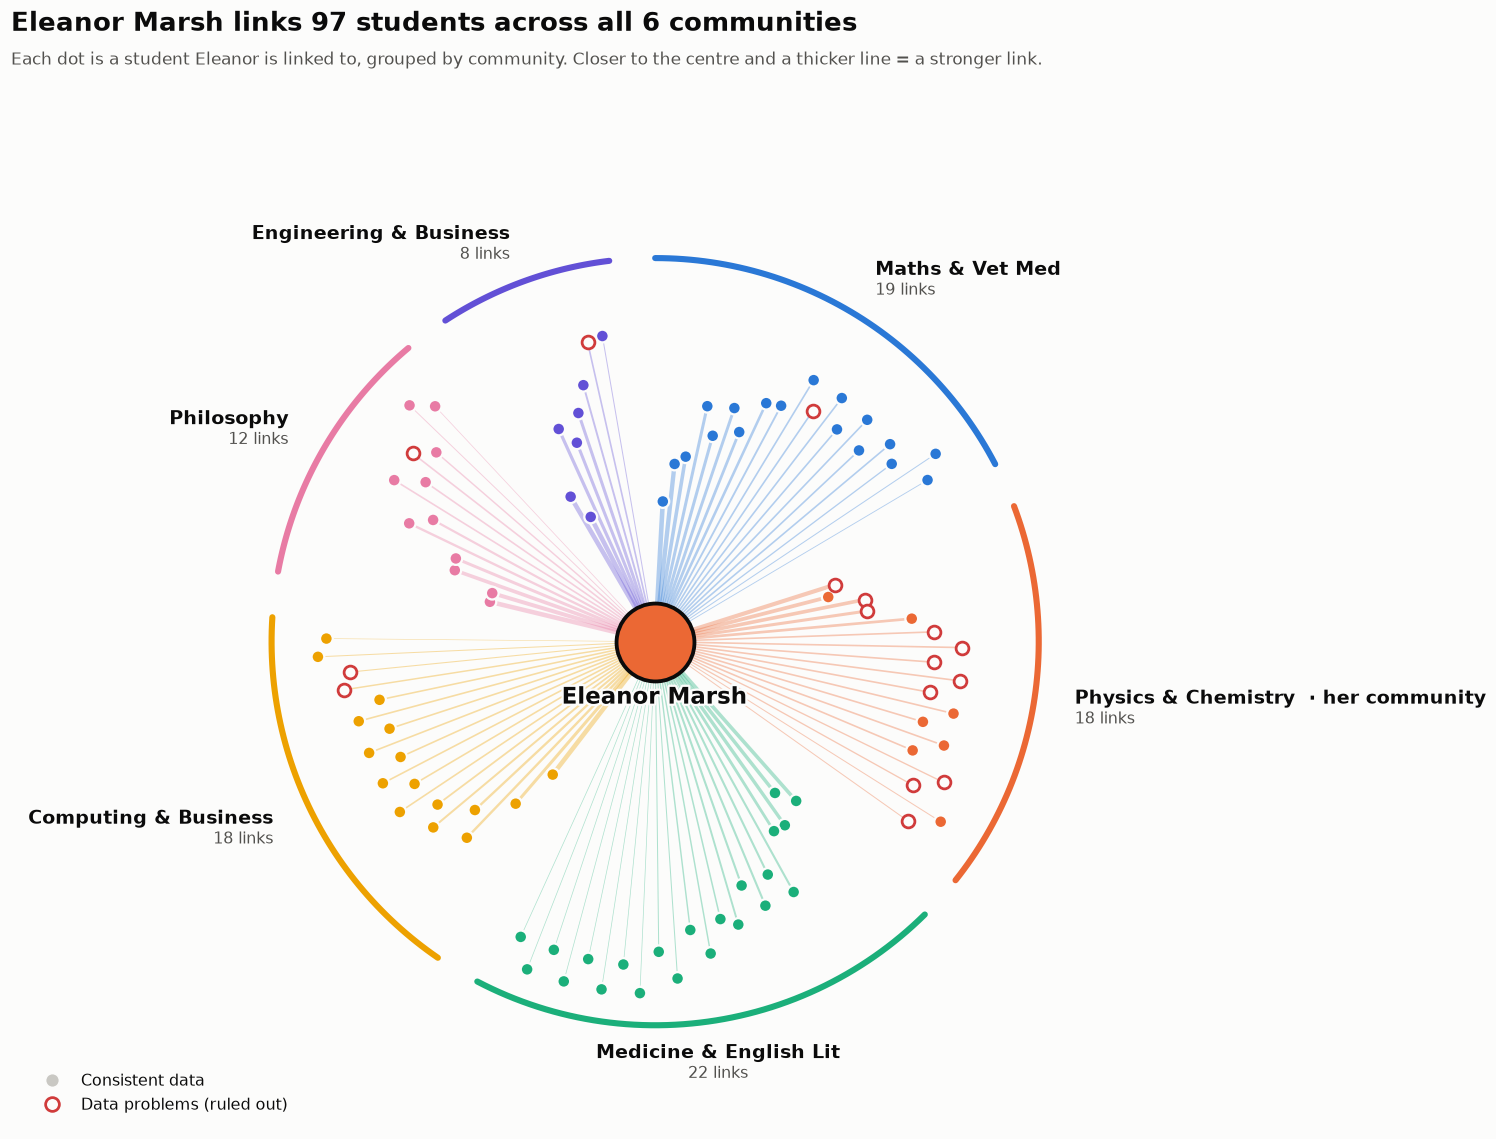

In [ ]:
#The hero chart
nbrs = pd.DataFrame([{'Student': v, 'Community': partition[v], 'Strength': d['weight'],
                      'Consistent': CONSISTENT[v]} for v, d in G[target].items()])
nbrs['Community'] = pd.Categorical(nbrs['Community'], categories=sorted(nbrs['Community'].unique()))
nbrs = nbrs.sort_values(['Community', 'Strength'], ascending=[True, False])

gap = 0.12                                         # radians between community sectors
span = 2 * np.pi - gap * nbrs['Community'].nunique()
angle, sectors = np.pi / 2, {}
for c, grp in nbrs.groupby('Community', observed=True):
    width = span * len(grp) / len(nbrs)
    a = angle - np.linspace(0, width, len(grp) + 2)[1:-1]
    nbrs.loc[grp.index, 'Angle'] = a
    sectors[c] = (angle, angle - width)
    angle -= width + gap
s = nbrs['Strength']
nbrs['Radius'] = 1.0 - 0.55 * (s - s.min()) / (s.max() - s.min())   # stronger link = closer to the centre
nbrs['Radius'] += np.where(np.arange(len(nbrs)) % 2, 0.04, -0.04)    # stagger neighbours so dots don't touch
nbrs['x'], nbrs['y'] = nbrs['Radius'] * np.cos(nbrs['Angle']), nbrs['Radius'] * np.sin(nbrs['Angle'])

fig, ax = plt.subplots(figsize=(12, 11))
own = partition[target]
headline(fig, f'{target} links {len(nbrs)} students across all {len(sectors)} communities',
         f'Each dot is a student {target.split()[0]} is linked to, grouped by community. '
         'Closer to the centre and a thicker line = a stronger link.')
for c, (a0, a1) in sectors.items():
    arc = np.linspace(a0, a1, 60)
    ax.plot(1.12 * np.cos(arc), 1.12 * np.sin(arc), color=COM_COLOR[c], lw=4, solid_capstyle='round')
    mid = (a0 + a1) / 2
    n_c = (nbrs['Community'] == c).sum()
    ha = 'left' if np.cos(mid) > 0.2 else 'right' if np.cos(mid) < -0.2 else 'center'
    label = f'{COM_NAME[c]}' + ('  · her community' if c == own else '')
    ax.text(1.24 * np.cos(mid), 1.24 * np.sin(mid) + 0.025, label, ha=ha, va='center', fontsize=12.5, weight='semibold')
    ax.text(1.24 * np.cos(mid), 1.24 * np.sin(mid) - 0.035, f'{n_c} links', ha=ha, va='center', fontsize=10.5, color=INK_2)
for _, r in nbrs.iterrows():
    ax.plot([0, r['x']], [0, r['y']], color=COM_COLOR[r['Community']], alpha=0.35,
            lw=0.4 + 2.6 * (r['Strength'] - s.min()) / (s.max() - s.min()), zorder=1)
ok, bad = nbrs[nbrs['Consistent']], nbrs[~nbrs['Consistent']]
ax.scatter(ok['x'], ok['y'], s=70, c=[COM_COLOR[c] for c in ok['Community']], edgecolors=SURFACE, linewidths=1.5, zorder=3)
ax.scatter(bad['x'], bad['y'], s=70, c=SURFACE, edgecolors=CRITICAL, linewidths=1.8, zorder=3)
ax.scatter([0], [0], s=2600, c=COM_COLOR[own], edgecolors=INK, linewidths=2.5, zorder=5)
ax.text(0, -0.13, target, ha='center', va='top', fontsize=15, weight='bold', path_effects=HALO, zorder=6)
ax.legend(handles=[Line2D([], [], marker='o', ls='', mfc=QUIET, mec=SURFACE, ms=9, label='Consistent data'),
                   Line2D([], [], marker='o', ls='', mfc=SURFACE, mec=CRITICAL, mew=1.8, ms=9, label='Data problems (ruled out)')],
          loc='lower left', fontsize=10.5)
ax.set_xlim(-1.85, 1.85); ax.set_ylim(-1.42, 1.42); ax.set_aspect('equal'); ax.axis('off')
plt.subplots_adjust(bottom=0.02, left=0.02, right=0.98)
plt.show()

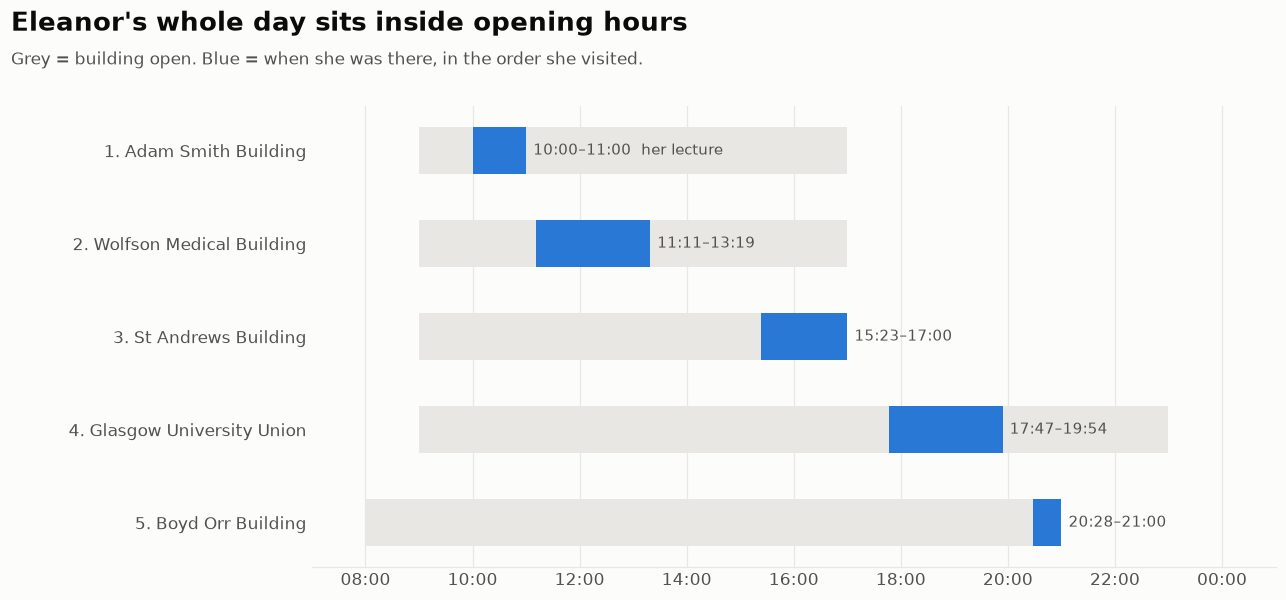

In [ ]:
#Day vs Opening Hours
day = df_logs[df_logs['Student ID'] == TARGET_ID].sort_values('Start').reset_index(drop=True)
subject = df_people.loc[df_people['Student ID'] == TARGET_ID, 'Subject'].iloc[0]
lect_b, lect_s, lect_e = LECTURES.get(subject, (None, 0, 0))

fig, ax = plt.subplots(figsize=(12, 0.75 * len(day) + 2.2))
headline(fig, f"{target.split()[0]}'s whole day sits inside opening hours",
         'Grey = building open. Blue = when she was there, in the order she visited.')
for i, r in day.iterrows():
    o, c = hours.loc[r['Location'], ['Open', 'Close']]
    y = len(day) - 1 - i
    ax.barh(y, min(c, 26 * 60) - o, left=o, height=0.5, color=GRID)
    ax.barh(y, r['Duration'], left=r['Start'], height=0.5, color=SERIES[0])
    note = '  her lecture' if (r['Location'] == lect_b and r['Start'] == lect_s and r['End'] == lect_e) else ''
    ax.text(r['End'] + 8, y, f"{r['Time'][:2]}:{r['Time'][2:4]}–{r['Time'][5:7]}:{r['Time'][7:]}{note}",
            va='center', fontsize=10, color=INK_2)
ax.set_yticks(range(len(day)), [f'{i + 1}. {loc}' for i, loc in enumerate(day['Location'])][::-1])
ticks = range(8 * 60, 25 * 60, 120)
ax.set_xticks(ticks, [f'{(t // 60) % 24:02d}:00' for t in ticks])
ax.set_xlim(7 * 60, 25 * 60); ax.xaxis.grid(True); ax.set_axisbelow(True)
ax.spines['left'].set_visible(False)
plt.subplots_adjust(left=0.24, right=0.97, bottom=0.12)
plt.show()

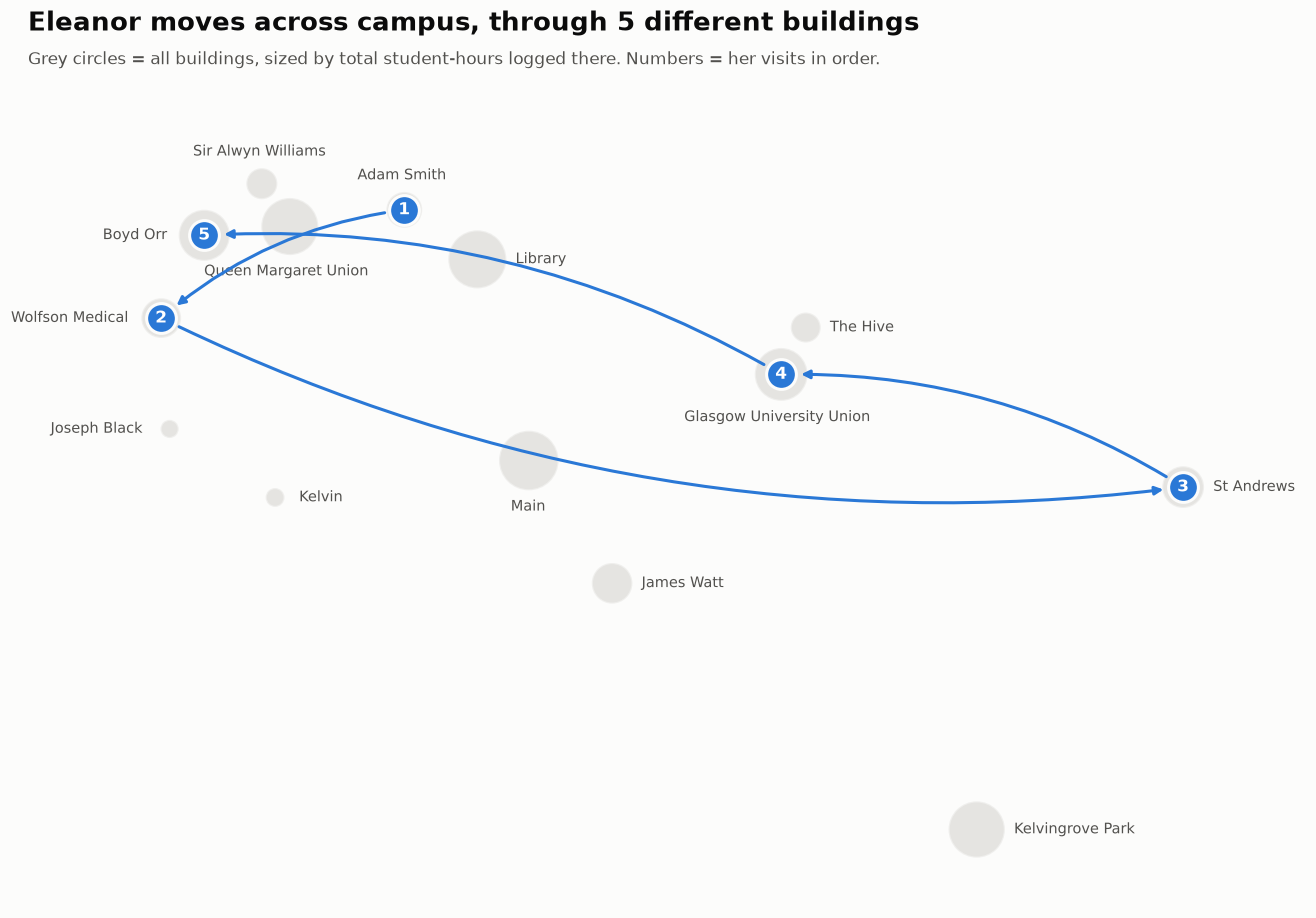

In [ ]:
#Routes
xy = df_location['Geolocation'].str.strip('{}').str.split(expand=True).astype(float)
df_location['Lat'], df_location['Lon'] = xy[0], xy[1]
loc = df_location.set_index('Building Name')
hours_logged = logs.groupby('Location')['Duration'].sum() / 60

fig, ax = plt.subplots(figsize=(12, 8.5))
headline(fig, f"{target.split()[0]} moves across campus, through {day['Location'].nunique()} different buildings",
         'Grey circles = all buildings, sized by total student-hours logged there. Numbers = her visits in order.')
ax.scatter(loc['Lon'], loc['Lat'], s=loc.index.map(hours_logged).fillna(0) * 9, color=QUIET, alpha=0.45,
           edgecolors=SURFACE, linewidths=1.5, zorder=1)
SIDE = {'Queen Margaret Union': 'below', 'Sir Alwyn Williams Building': 'above', 'Boyd Orr Building': 'left',
        'Wolfson Medical Building': 'left', 'Joseph Black Building': 'left', 'Glasgow University Union': 'below',
        'Main Building': 'below', 'Adam Smith Building': 'above'}
for name, r in loc.iterrows():
    gap = np.sqrt(max(hours_logged.get(name, 0) * 9, 380)) / 2 + 6 # clears the circle (and route marker)
    dx, dy = {'left': (-gap, 0), 'above': (0, gap), 'below': (0, -gap)}.get(SIDE.get(name), (gap, 0))
    ax.annotate(name.replace(' Building', ''), (r['Lon'], r['Lat']), xytext=(dx, dy), textcoords='offset points',
                ha='right' if dx < 0 else 'center' if dx == 0 else 'left',
                va='bottom' if dy > 0 else 'top' if dy < 0 else 'center',
                fontsize=9.5, color=INK_2, path_effects=HALO, zorder=2)
route = loc.loc[day['Location'], ['Lon', 'Lat']].values
for (x0, y0), (x1, y1) in zip(route[:-1], route[1:]):
    ax.annotate('', (x1, y1), (x0, y0), arrowprops=dict(arrowstyle='-|>', color=SERIES[0], lw=2,
                shrinkA=13, shrinkB=13, connectionstyle='arc3,rad=0.15'), zorder=3)
for i, (x, y) in enumerate(route):
    ax.scatter(x, y, s=380, color=SERIES[0], edgecolors=SURFACE, linewidths=2, zorder=4)
    ax.text(x, y, str(i + 1), ha='center', va='center', color='white', weight='bold', fontsize=11, zorder=5)
ax.set_xticks([]); ax.set_yticks([])
for side in ax.spines.values(): side.set_visible(False)
ax.margins(0.12)
plt.subplots_adjust(bottom=0.02, left=0.02, right=0.98)
plt.show()

In [ ]:
#Link list and shared in common
ties = pd.DataFrame([{'Student': v, 'Community': COM_NAME[partition[v]],
                      'Shared societies': ', '.join(d['societies']) or '–',
                      'Minutes together': d['minutes'], 'Where': ', '.join(d['places']) or '–'}
                     for v, d in G[target].items()])
ties.sort_values(['Community', 'Minutes together'], ascending=[True, False]).reset_index(drop=True)

,Student,Community,Shared societies,Minutes together,Where
0,Chloe Tyler,Computing & Business,Skate Society,127,Glasgow University Union
1,Gary Singh,Computing & Business,–,92,Glasgow University Union
2,Sharon Ellis,Computing & Business,–,90,Glasgow University Union
3,Matthew Smith,Computing & Business,–,76,"Adam Smith Building, Glasgow University Union"
4,Rosemary Jones,Computing & Business,–,67,"Glasgow University Union, St Andrews Building"
...,...,...,...,...,...
92,Danielle Cox,Physics & Chemistry,"Juggling Society, Skate Society",0,–
93,Deborah Carter,Physics & Chemistry,LGBTQ+ Students Association,0,–
94,Henry Sharp,Physics & Chemistry,Pole Dancing Club,0,–
95,Suzanne Fox,Physics & Chemistry,Pole Dancing Club,0,–
